<a href="https://colab.research.google.com/github/huynhngochan1368-hub/TH_HocMay/blob/main/Baitaptrenlop_Tuan01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
#Bài 1. Giả sử có một tập dữ liệu giả định với các cột Diện tích nhà (m2) và Giá bán (triệu VND).
#1.Xây dựng một mô hình hồi quy tuyến tính đơn giản để dự đoán Giá bán dựa trên Diện tích nhà.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
#mô hình hồi quy tuyến tính đơn giản
np.random.seed(42)
X_don_gian=np.random.uniform(30,120,50).reshape(-1,1)
y_don_gian=35*X_don_gian.squeeze()+200 + np.random.normal(0,10,50)
model_simple = LinearRegression()
model_simple.fit(X_don_gian, y_don_gian)
print("=== 1. HỒI QUY TUYẾN TÍNH ĐƠN GIẢN ===")
print(f"Hệ số góc (Slope): {model_simple.coef_[0]:2f}")
print(f"Hệ số chặn (Intercept):{model_simple.intercept_:.2f}")
# Thêm nhiều số lượng dữ liệu và độ nhiễu
#Giả lập 500 mẫu với độ nhiễu lớn hơn (std=400)
X_nhieu_nhieu=np.random.uniform(30,150,500).reshape(-1,1)
y_nhieu_nhieu=35*X_nhieu_nhieu.squeeze()+200 + np.random.normal(0,400,500)
model_noisy=LinearRegression()
model_noisy.fit(X_nhieu_nhieu,y_nhieu_nhieu)
print("\n=== 2. THÊM NHIỀU DỮ LIỆU & ĐỘ NHIỄU ===")
print(f"Hệ số góc mới:{model_noisy.coef_[0]:.2f}")
print(f"R2 score mới:{model_noisy.score(X_nhieu_nhieu,y_nhieu_nhieu):.2f}")
#thêm các biến đầu vào khác để nâng cao tính phức tạp của mô hình
#tạo các biến:Diện tích (m2) , số phòng ngủ , tuổi nhà ( năm)
n_samples = 500
dien_tich = np.random.uniform(30, 150, n_samples)
so_phong_ngu = np.random.randint(1, 5, n_samples)
tuoi_nha = np.random.uniform(0, 20, n_samples)

# Giá bán phụ thuộc vào nhiều yếu tố
gia_ban_da_bien = (35 * dien_tich) + (150 * so_phong_ngu) - (20 * tuoi_nha) + 200 + np.random.normal(0, 200, n_samples)

X_da_bien = pd.DataFrame({
    'DienTich': dien_tich,
    'SoPhongNgu': so_phong_ngu,
    'TuoiNha': tuoi_nha
})

model_multi = LinearRegression()
model_multi.fit(X_da_bien, gia_ban_da_bien)

print("\n=== 3. HỒI QUY TUYẾN TÍNH ĐA BIẾN ===")
for col, coef in zip(X_da_bien.columns, model_multi.coef_):
    print(f"Trọng số của {col}: {coef:.2f}")
print(f"R2 Score (Đa biến): {r2_score(gia_ban_da_bien, model_multi.predict(X_da_bien)):.4f}")


=== 1. HỒI QUY TUYẾN TÍNH ĐƠN GIẢN ===
Hệ số góc (Slope): 34.975174
Hệ số chặn (Intercept):201.71

=== 2. THÊM NHIỀU DỮ LIỆU & ĐỘ NHIỄU ===
Hệ số góc mới:34.54
R2 score mới:0.91

=== 3. HỒI QUY TUYẾN TÍNH ĐA BIẾN ===
Trọng số của DienTich: 34.94
Trọng số của SoPhongNgu: 161.20
Trọng số của TuoiNha: -20.71
R2 Score (Đa biến): 0.9770


=== DỰ ĐOÁN KHẢ NĂNG MẮC BỆNH (LOGISTIC REGRESSION) ===
Độ chính xác (Accuracy): 80.00%

Ma trận nhầm lẫn (Confusion Matrix):
[[15  3]
 [ 9 33]]

Báo cáo chi tiết:
              precision    recall  f1-score   support

           0       0.62      0.83      0.71        18
           1       0.92      0.79      0.85        42

    accuracy                           0.80        60
   macro avg       0.77      0.81      0.78        60
weighted avg       0.83      0.80      0.81        60



/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


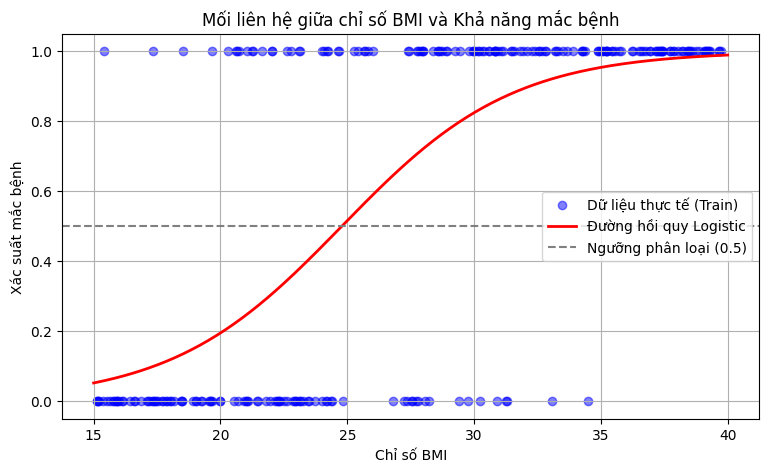

In [5]:
#Bài 2: Dự đoán khả năng mắc bệnh dựa trên chỉ số BMI
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

np.random.seed(42)

# 1. Tạo dữ liệu giả lập logic (BMI cao -> Xác suất mắc bệnh cao)
n_samples = 300
bmi = np.random.uniform(15, 40, n_samples)

# Hàm Sigmoid tạo xác suất mắc bệnh dựa trên BMI
p = 1 / (1 + np.exp(-(0.35 * (bmi - 25))))
mac_benh = np.random.binomial(1, p)

df_bmi = pd.DataFrame({'BMI': bmi, 'MacBenh': mac_benh})

# Chia tập dữ liệu Train (80%) / Test (20%)
X = df_bmi[['BMI']]
y = df_bmi['MacBenh']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2 & 3. Sử dụng scikit-learn để tạo và huấn luyện mô hình Logistic Regression
model_logistic = LogisticRegression()
model_logistic.fit(X_train, y_train)

# 4. Dự đoán xác suất và nhãn mắc bệnh trên tập kiểm tra
y_pred = model_logistic.predict(X_test)
y_prob = model_logistic.predict_proba(X_test)[:, 1] # Xác suất nhãn 1

# 5. Đánh giá hiệu quả mô hình
acc = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print("=== DỰ ĐOÁN KHẢ NĂNG MẮC BỆNH (LOGISTIC REGRESSION) ===")
print(f"Độ chính xác (Accuracy): {acc * 100:.2f}%")
print("\nMa trận nhầm lẫn (Confusion Matrix):")
print(cm)
print("\nBáo cáo chi tiết:")
print(classification_report(y_test, y_pred))

# 6. Trực quan hóa dữ liệu và đường hồi quy logistic
bmi_grid = np.linspace(15, 40, 300).reshape(-1, 1)
prob_grid = model_logistic.predict_proba(bmi_grid)[:, 1]

plt.figure(figsize=(9, 5))
plt.scatter(X_train, y_train, color='blue', alpha=0.5, label='Dữ liệu thực tế (Train)')
plt.plot(bmi_grid, prob_grid, color='red', linewidth=2, label='Đường hồi quy Logistic')
plt.axhline(0.5, color='gray', linestyle='--', label='Ngưỡng phân loại (0.5)')
plt.title('Mối liên hệ giữa chỉ số BMI và Khả năng mắc bệnh')
plt.xlabel('Chỉ số BMI')
plt.ylabel('Xác suất mắc bệnh')
plt.legend()
plt.grid(True)
plt.show()

In [6]:
#Bài 3. Hãy chọn 1 bộ dữ liệu tùy ý (HD: có thể tham khảo trên các trang mạng, ví dụ nhưKaggle) và thực hiện các bước cần thiết để có được mô hình hồi qui ứng với bộ dữ liệu đã chọn.
import pandas as pd
import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 1. Tải bộ dữ liệu Diabetes từ scikit-learn
diabetes = load_diabetes(as_frame=True)
df_diabetes = diabetes.frame

print("=== BÀI 3: BỘ DỮ LIỆU TIỂU ĐƯỜNG (DIABETES) ===")
print("5 dòng dữ liệu đầu tiên:")
print(df_diabetes.head())

# 2. Phân chia Đặc trưng (Features) và Mục tiêu (Target - Mức độ tiến triển bệnh)
X = df_diabetes.drop(columns=['target'])
y = df_diabetes['target']

# 3. Chia tập Train / Test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Xây dựng và huấn luyện mô hình Hồi quy tuyến tính
model_diabetes = LinearRegression()
model_diabetes.fit(X_train, y_train)

# 5. Dự đoán và đánh giá hiệu năng
y_pred = model_diabetes.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\n=== KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH ===")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"R2 Score: {r2:.4f}")

=== BÀI 3: BỘ DỮ LIỆU TIỂU ĐƯỜNG (DIABETES) ===
5 dòng dữ liệu đầu tiên:
        age       sex       bmi        bp  ...        s4        s5        s6  target
0  0.038076  0.050680  0.061696  0.021872  ... -0.002592  0.019907 -0.017646   151.0
1 -0.001882 -0.044642 -0.051474 -0.026328  ... -0.039493 -0.068332 -0.092204    75.0
2  0.085299  0.050680  0.044451 -0.005670  ... -0.002592  0.002861 -0.025930   141.0
3 -0.089063 -0.044642 -0.011595 -0.036656  ...  0.034309  0.022688 -0.009362   206.0
4  0.005383 -0.044642 -0.036385  0.021872  ... -0.002592 -0.031988 -0.046641   135.0

[5 rows x 11 columns]

=== KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH ===
Mean Squared Error (MSE): 2900.19
Root Mean Squared Error (RMSE): 53.85
Mean Absolute Error (MAE): 42.79
R2 Score: 0.4526
